1. Imports

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
sns.set_theme()

2. Load train/validation/test

In [4]:
PROJECT_ROOT = Path.cwd().parent
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "validation.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

FEATURE_COLUMNS = ["brand", "price", "stock", "rating"]
TARGET_COLUMNS = "category"

x_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMNS].astype(str)

x_val = val_df[FEATURE_COLUMNS]
y_val = val_df[TARGET_COLUMNS].astype(str)

x_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET_COLUMNS].astype(str)

print("Train:", x_train.shape)
print("Val:", x_val.shape)
print("Test:", x_test.shape)

Train: (156, 4)
Val: (20, 4)
Test: (20, 4)


3. Build preprocessing pipeline

In [5]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))])
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, ["price", "stock", "rating"]),
        ("categorical", categorical_pipeline, ["brand"])])
    return preprocessor

4. Train Logistic Regression

In [6]:
logistic_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))])

logistic_model.fit(x_train, y_train)
logistic_val_pred = logistic_model.predict(x_val)
logistic_val_acc = accuracy_score(y_val, logistic_val_pred)
print("Logistic Regression Accuracy:", round(logistic_val_acc, 4))

Logistic Regression Accuracy: 0.95


5. Train Random Forest

In [10]:
random_forest_model = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1))])

random_forest_model.fit(x_train, y_train)
rf_val_pred = random_forest_model.predict(x_val)
rf_val_acc = accuracy_score(y_val, rf_val_pred)

print("Random Forest Accuracy:", round(rf_val_acc, 4))

Random Forest Accuracy: 0.95


6. Compare Models

In [11]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Validation Accuracy": [
        logistic_val_acc,
        rf_val_acc
    ]
})
display(comparison.sort_values("Validation Accuracy", ascending=False))

if logistic_val_acc >= rf_val_acc:
    best_model = logistic_model
    best_model_name = "Logistic Regression"
else:
    best_model = random_forest_model
    best_model_name = "Random Forest"

print("Best Model:", best_model_name)

,Model,Validation Accuracy
0,Logistic Regression,0.95
1,Random Forest,0.95


Best Model: Logistic Regression


7. Final test evaluation

In [12]:
test_pred = best_model.predict(x_test)
test_acc = accuracy_score(y_test, test_pred)

print("Best Model:", best_model_name)
print("Test Accuracy:", round(test_acc, 4))

print(classification_report(y_test, test_pred, zero_division=0))

Best Model: Logistic Regression
Test Accuracy: 0.9
              precision    recall  f1-score   support

         CPU       0.67      1.00      0.80         4
        Case       1.00      1.00      1.00         2
         GPU       1.00      0.60      0.75         5
     Monitor       1.00      1.00      1.00         2
 Motherboard       1.00      1.00      1.00         1
       Mouse       1.00      1.00      1.00         1
         RAM       1.00      1.00      1.00         3
         SSD       1.00      1.00      1.00         2

    accuracy                           0.90        20
   macro avg       0.96      0.95      0.94        20
weighted avg       0.93      0.90      0.90        20



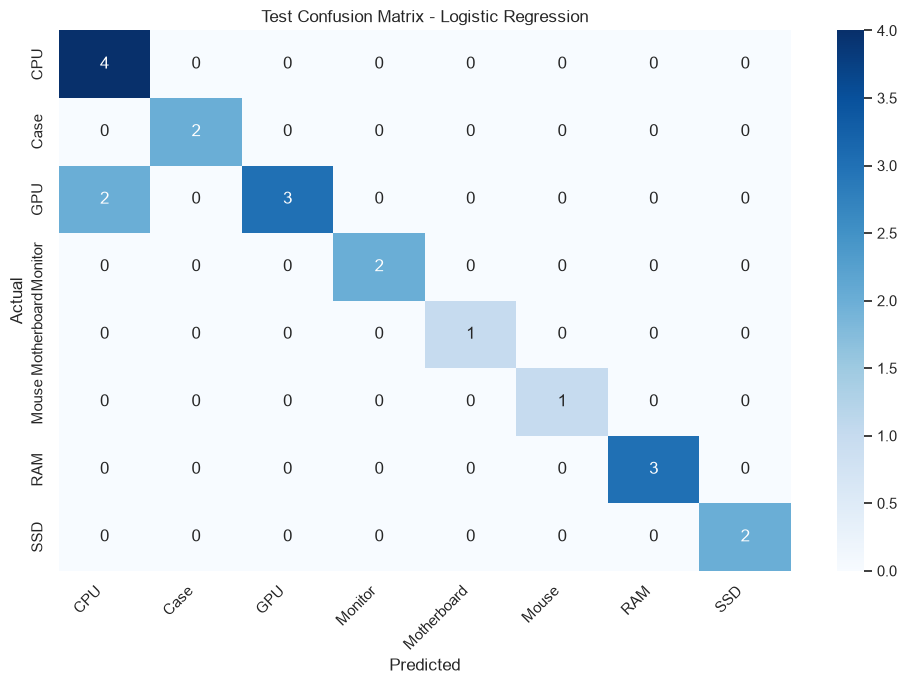

In [13]:
labels = sorted(set(y_test) | set(test_pred))

cm = confusion_matrix(y_test, test_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Test Confusion Matrix - {best_model_name}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

8. Save Model

In [14]:
joblib.dump(logistic_model, MODELS_DIR / "logistic_regression_classification.joblib")
joblib.dump(random_forest_model, MODELS_DIR / "random_forest_classification.joblib")

metadata = {
    "feature_columns": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMNS,
    "selected_model" : best_model_name,
    "logistic_validation_accuracy" : float(logistic_val_acc),
    "random_forest_validation_accuracy" : float(rf_val_acc),
    "test_accuracy" : float(test_acc)
}

with open(
    MODELS_DIR / "classification_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Models saved in: ", MODELS_DIR)

Models saved in:  /Users/macbookpro/PycharmProjects/Techcart_ai/models


9. Predict a new product

In [15]:
sample_product = pd.DataFrame([{
    "brand": (
        x_train["brand"].dropna().iloc[0]
        if x_train["brand"].notna().any()
        else "Unknown"
    ),
    "price": x_train["price"].median(),
    "stock": x_train["stock"].median(),
    "rating": x_train["rating"].median()}])

loaded_model = joblib.load(MODELS_DIR / "random_forest_classification.joblib")

prediction = loaded_model.predict(sample_product)

display(sample_product)
print("Predicted category:", prediction[0])

,brand,price,stock,rating
0,Corsair,176.65,16.0,4.7


Predicted category: PSU
